This project analyzes retail transaction data using machine learning techniques and market basket analysis. The goal is to understand customer purchasing behavior, predict sales, classify customers, and recommend products frequently purchased together.

Objectives-

1. Predict customer purchase behavior

2. Perform Market Basket Analysis

3. Recommend products

4. Classify customers

Dataset used: Retail Transaction Dataset

Import Libraries

In [28]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)   # hides the repeated jupyter_client warnings
warnings.filterwarnings("ignore", category=UserWarning)

In [29]:
!pip install -U mlxtend

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error, r2_score

from mlxtend.frequent_patterns import apriori, association_rules
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)
print("✅ All libraries imported successfully")

✅ All libraries imported successfully


In [32]:
df = pd.read_csv("Retail_Transaction_Dataset.csv")
df.head()
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 10 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   CustomerID          100000 non-null  int64  
 1   ProductID           100000 non-null  str    
 2   Quantity            100000 non-null  int64  
 3   Price               100000 non-null  float64
 4   TransactionDate     100000 non-null  str    
 5   PaymentMethod       100000 non-null  str    
 6   StoreLocation       100000 non-null  str    
 7   ProductCategory     100000 non-null  str    
 8   DiscountApplied(%)  100000 non-null  float64
 9   TotalAmount         100000 non-null  float64
dtypes: float64(3), int64(2), str(5)
memory usage: 14.9 MB


,CustomerID,Quantity,Price,DiscountApplied(%),TotalAmount
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,500463.982180,5.009290,55.067344,10.020155,248.334955
std,288460.917524,2.579808,25.971567,5.779534,184.554792
min,14.000000,1.000000,10.000430,0.000046,8.274825
25%,250693.750000,3.000000,32.549474,5.001013,95.163418
50%,499679.000000,5.000000,55.116789,10.030353,200.368393
75%,751104.750000,7.000000,77.456763,15.018367,362.009980
max,999997.000000,9.000000,99.999284,19.999585,896.141242


Data Preprocessing / Cleaning

In [33]:
df["TransactionDate"] = pd.to_datetime(df["TransactionDate"], errors='coerce')
df = df.dropna(subset=["TransactionDate"])
df.isnull().sum()

CustomerID            0
ProductID             0
Quantity              0
Price                 0
TransactionDate       0
PaymentMethod         0
StoreLocation         0
ProductCategory       0
DiscountApplied(%)    0
TotalAmount           0
dtype: int64

Data Visualization

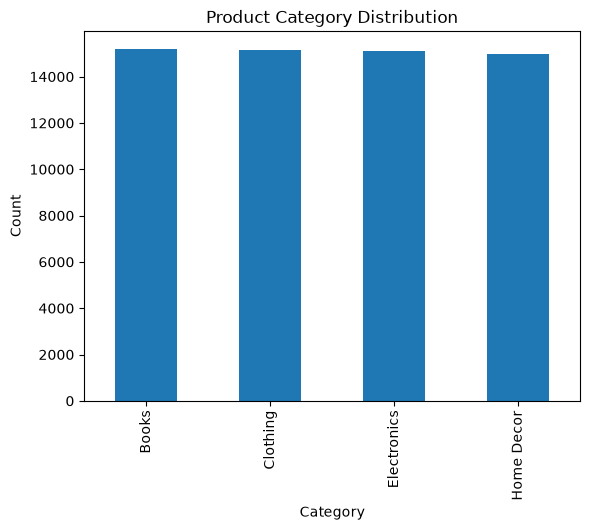

In [34]:
#Product Category Distribution
df["ProductCategory"].value_counts().plot(kind="bar")

plt.title("Product Category Distribution")
plt.xlabel("Category")
plt.ylabel("Count")

plt.show()

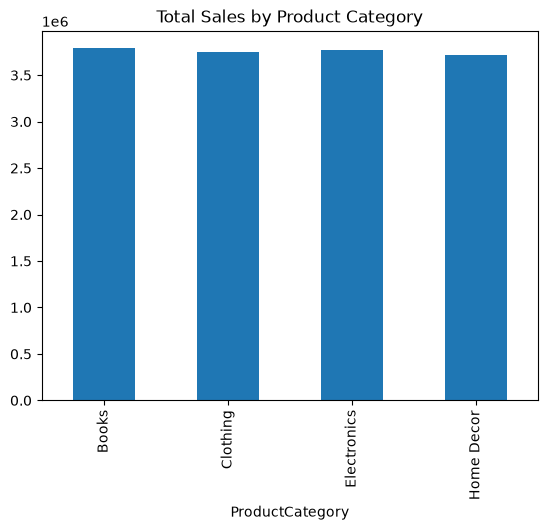

In [35]:
#Total Sales by Category
df.groupby("ProductCategory")["TotalAmount"].sum().plot(kind="bar")

plt.title("Total Sales by Product Category")

plt.show()

Sales Prediction using Linear Regression

In [36]:
X = df[["Quantity","Price","DiscountApplied(%)"]]
y = df["TotalAmount"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
pred = model.predict(X_test)
X_test

,Quantity,Price,DiscountApplied(%)
95285,2,64.679864,2.616768
99749,8,84.004913,2.393342
58642,3,93.184230,4.939669
58059,9,36.724426,13.338306
15501,2,13.271513,2.272213
...,...,...,...
81990,8,50.107932,8.171909
18301,9,98.964251,18.573373
11323,1,36.343620,16.265721
85424,9,11.984221,12.501425


In [37]:
#Model Evaluation
mse = mean_squared_error(y_test, pred)
print("Mean Squared Error:", mse)

Mean Squared Error: 3679.1496153102207


Customer Segmentation (Classification)

In [38]:
# Create spending categories

df['CustomerSegment'] = pd.cut(
    df['TotalAmount'],
    bins=[-float('inf'), 100, 300, float('inf')],
    labels=['Low', 'Medium', 'High']
)

print(df['CustomerSegment'].value_counts())

CustomerSegment
Medium    24383
High      20202
Low       15854
Name: count, dtype: int64


In [39]:
# Select independent variables

X = df[
    ['Quantity', 'Price', 'DiscountApplied(%)']
]

# Encode spending categories

y = df['CustomerSegment'].cat.codes

# Check category mapping

print({
    category: code
    for code, category in enumerate(
        df['CustomerSegment'].cat.categories
    )
})

{'Low': 0, 'Medium': 1, 'High': 2}


In [40]:
from sklearn.tree import DecisionTreeClassifier

# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train model

model = DecisionTreeClassifier(random_state=42)

model.fit(X_train, y_train)

# Make predictions

y_pred = model.predict(X_test)


In [41]:
# Model evaluation

print("Accuracy:",
      accuracy_score(y_test, y_pred))

print("Precision:",
      precision_score(
          y_test, y_pred,
          average='weighted',
          zero_division=0
      ))

print("Recall:",
      recall_score(
          y_test, y_pred,
          average='weighted',
          zero_division=0
      ))

print("F1 Score:",
      f1_score(
          y_test, y_pred,
          average='weighted',
          zero_division=0
      ))

Accuracy: 0.992885506287227
Precision: 0.9928908880207388
Recall: 0.992885506287227
F1 Score: 0.9928864443588241


In [42]:
# Detailed classification report

print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1, 2],
        target_names=['Low', 'Medium', 'High'],
        zero_division=0
    )
)

              precision    recall  f1-score   support

         Low       1.00      0.99      0.99      3171
      Medium       0.99      0.99      0.99      4877
        High       0.99      0.99      0.99      4040

    accuracy                           0.99     12088
   macro avg       0.99      0.99      0.99     12088
weighted avg       0.99      0.99      0.99     12088



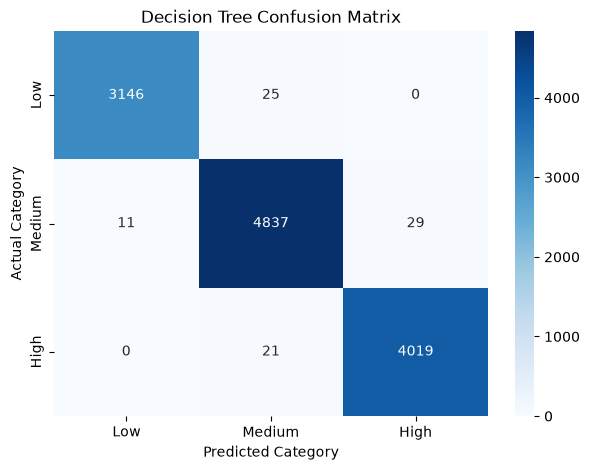

In [43]:
# Confusion Matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.show()

Market Basket Analysis (Apriori Algorithm)

In [44]:
basket = df.groupby(['CustomerID','ProductID'])['Quantity'].sum().unstack().fillna(0)
basket = basket.map(lambda x: 1 if x > 0 else 0)

In [45]:
#Apply Apriori
frequent_items = apriori(basket, min_support=0.02, use_colnames=True)
frequent_items.head(4)

,support,itemsets
0,0.252779,frozenset({A})
1,0.257109,frozenset({B})
2,0.257689,frozenset({C})
3,0.255166,frozenset({D})


In [46]:
from mlxtend.frequent_patterns import association_rules

rules = association_rules(frequent_items, metric="lift", min_threshold=0.1)

print("Rules created:", len(rules))

Rules created: 0


Association Rules

In [47]:
#Product Recommendation System
rules[['antecedents','consequents','support','confidence','lift']]

,antecedents,consequents,support,confidence,lift


In [48]:
print("Number of rules:", len(rules))
rules.head()

Number of rules: 0


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski


In [49]:
# Customer-level aggregation

customer_data = df.groupby('CustomerID').agg(
    Total_Spend=('TotalAmount', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Average_Record_Value=('TotalAmount', 'mean'),
    Total_Records=('TotalAmount', 'count')
).reset_index()

display(customer_data.head())

,CustomerID,Total_Spend,Total_Quantity,Average_Record_Value,Total_Records
0,42,502.656523,7,502.656523,1
1,59,139.612036,4,139.612036,1
2,65,548.006625,8,548.006625,1
3,87,41.515905,2,41.515905,1
4,98,166.934647,6,166.934647,1


**Create customer segments**

In [50]:
# Customer segmentation using total spending

customer_data['Customer_Segment'] = pd.qcut(
    customer_data['Total_Spend'].rank(method='first'),
    q=3,
    labels=['Low', 'Medium', 'High']
)

print(
    customer_data['Customer_Segment'].value_counts()
)

Customer_Segment
Low       19552
Medium    19552
High      19552
Name: count, dtype: int64


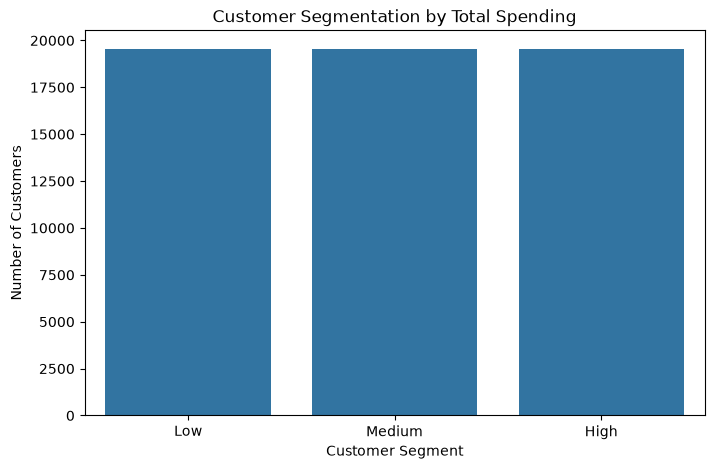

In [51]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=customer_data,
    x='Customer_Segment',
    order=['Low', 'Medium', 'High']
)

plt.title("Customer Segmentation by Total Spending")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.show()

**Compare spending across segments**

In [52]:
# Average spending by customer segment

segment_analysis = customer_data.groupby(
    'Customer_Segment',
    observed=True
).agg(
    Number_of_Customers=('CustomerID', 'count'),
    Average_Spending=('Total_Spend', 'mean'),
    Total_Revenue=('Total_Spend', 'sum')
)

print(segment_analysis)

                  Number_of_Customers  Average_Spending  Total_Revenue
Customer_Segment                                                      
Low                             19552         72.608088   1.419633e+06
Medium                          19552        211.270093   4.130753e+06
High                            19552        484.724318   9.477330e+06


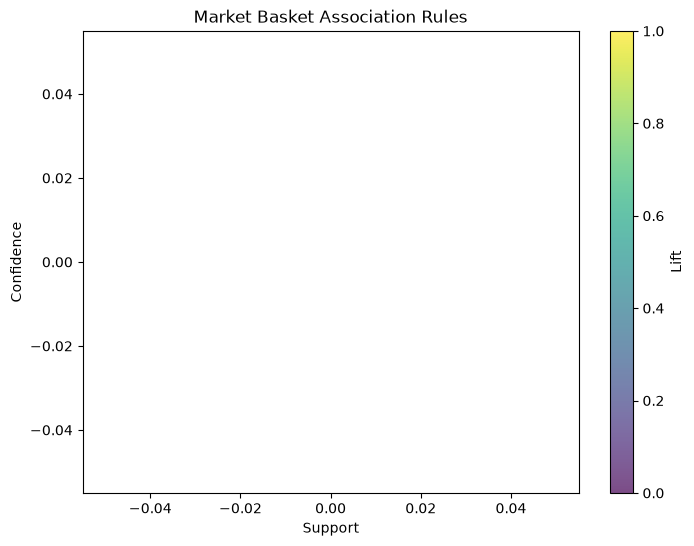

In [53]:
#Visualization of Association Rules
plt.figure(figsize=(8,6))

plt.scatter(
    rules['support'],
    rules['confidence'],
    c=rules['lift'],
    cmap='viridis',
    alpha=0.7
)

plt.colorbar(label='Lift')

plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Market Basket Association Rules")

plt.show()

Final Results
The Smart Retail Analytics System successfully performs:

Customer Insights
1. Identifies high-value customers
2. Segments customers into Low, Medium, High spenders

Sales Prediction

Predicts expected sales based on:
1. price
2. quantity
3. discount
4. category

Market Basket Analysis - Finds frequently bought products together
Product Recommendation - Suggests products based on association rules

Example recommendation:
If customer buys Electronics → recommend Accessories